In [ ]:
# Import the libraries required for this project
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds for reproducible experiments
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Display TensorFlow and GPU information
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Load the CIFAR-10 dataset

In [ ]:
# Download and load the CIFAR-10 dataset
(x_train_full, y_train_full), (x_test, y_test) = (
    keras.datasets.cifar10.load_data()
)

# Convert labels from shape (n, 1) to shape (n,)
y_train_full = y_train_full.squeeze()
y_test = y_test.squeeze()

# Define the ten image categories
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Display dataset dimensions
print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4049s 24us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


Explore and visualize the images

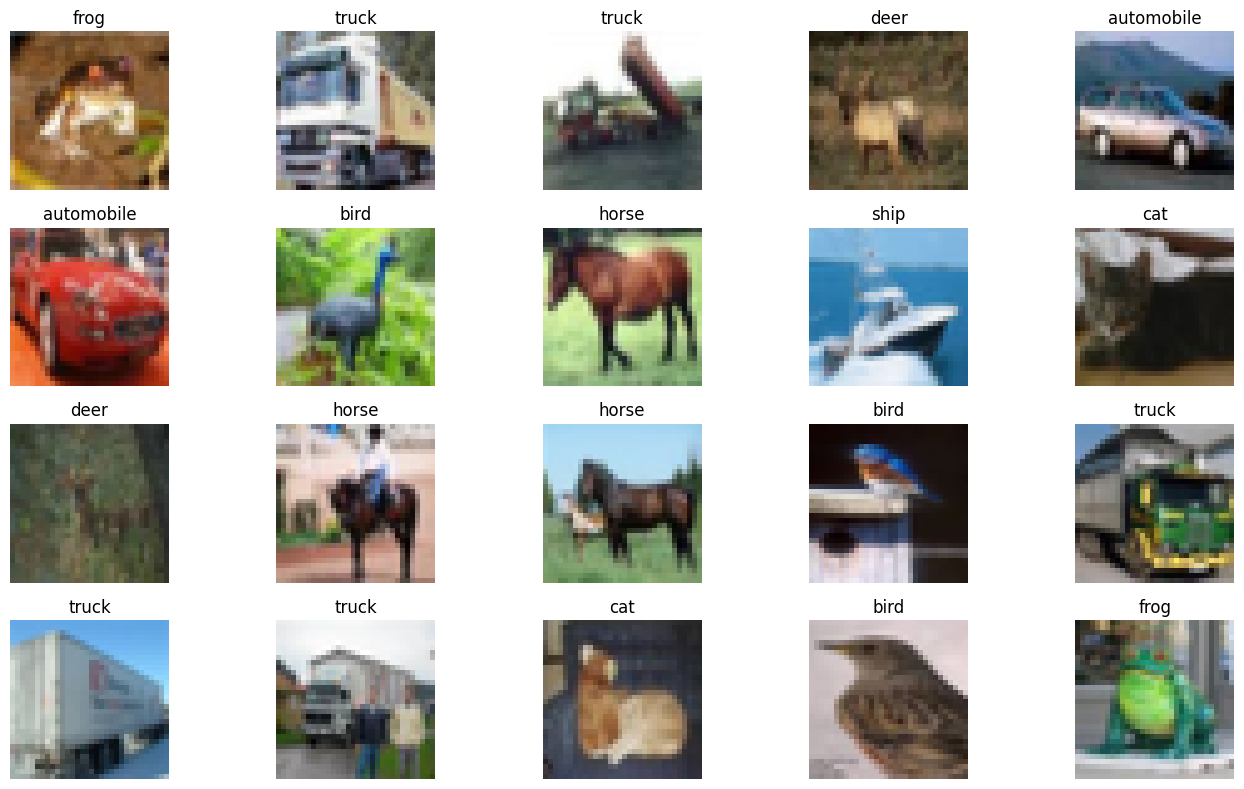

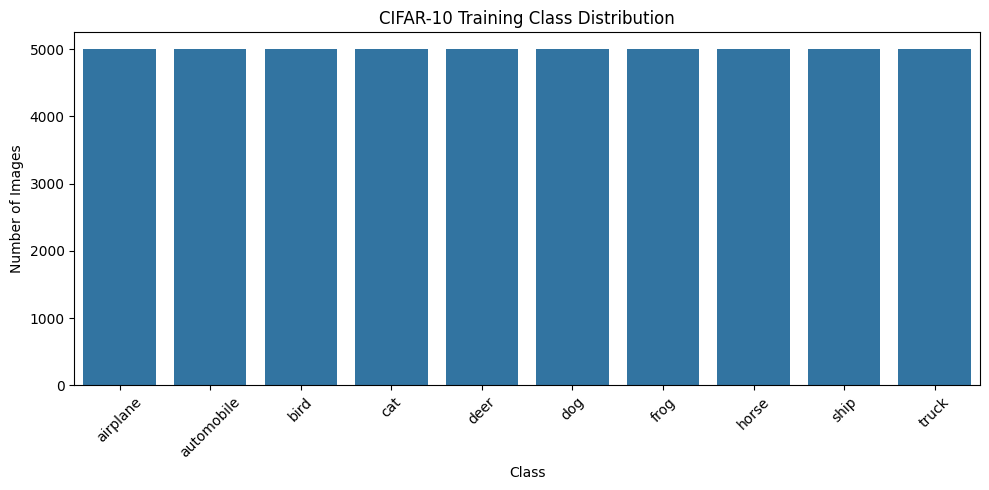

In [ ]:
# Display a sample of 20 images with their class labels
plt.figure(figsize=(14, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train_full[i])
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Count images in each category
class_counts = pd.Series(y_train_full).value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=class_names,
    y=[class_counts[i] for i in range(10)]
)
plt.xticks(rotation=45)
plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

Preprocess the data

In [ ]:
# Reserve part of the training set for validation
x_train = x_train_full[:-5000]
y_train = y_train_full[:-5000]

x_val = x_train_full[-5000:]
y_val = y_train_full[-5000:]

# Normalize pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Display the resulting dataset sizes
print("Training set:", x_train.shape)
print("Validation set:", x_val.shape)
print("Test set:", x_test.shape)

Training set: (45000, 32, 32, 3)
Validation set: (5000, 32, 32, 3)
Test set: (10000, 32, 32, 3)


Build the Basic CNN model

In [ ]:
# Build a CNN for classifying 32x32 RGB images
def build_basic_cnn():

    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),

        # Extract image features using convolution
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation="relu"),

        # Reduce spatial dimensions
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Learn more complex visual patterns
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),

        # Convert feature maps into a feature vector
        layers.Flatten(),

        # Perform classification
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),
        layers.Dense(10, activation="softmax")
    ])

    # Configure training and evaluation
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

cnn_model = build_basic_cnn()
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 15, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 362,282 (1.38 MB)

 Trainable params: 362,090 (1.38 MB)

 Non-trainable params: 192 (768.00 B)

Train the CNN

In [ ]:
# Save the best model and stop when validation performance stops improving
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train the CNN model
start_time = time.perf_counter()

history_cnn = cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

cnn_training_time = time.perf_counter() - start_time

# Load the best checkpoint
cnn_model = keras.models.load_model("best_cnn.keras")

# Evaluate on the untouched test set
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test accuracy: {cnn_accuracy:.4f}")
print(f"Test accuracy percentage: {cnn_accuracy * 100:.2f}%")
print(f"Training time: {cnn_training_time:.2f} seconds")

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.2170 - loss: 2.1809
Epoch 1: val_accuracy improved from None to 0.17080, saving model to best_cnn.keras

Epoch 1: finished saving model to best_cnn.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 44ms/step - accuracy: 0.2837 - loss: 1.9080 - val_accuracy: 0.1708 - val_loss: 2.4772 - learning_rate: 0.0010
Epoch 2/30
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4149 - loss: 1.5683
Epoch 2: val_accuracy improved from 0.17080 to 0.49500, saving model to best_cnn.keras

Epoch 2: finished saving model to best_cnn.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.4433 - loss: 1.5028 - val_accuracy: 0.4950 - val_loss: 1.4507 - learning_rate: 0.0010
Epoch 3/30
347/352 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5129 - loss: 1.3425
Epoch 3: val_accuracy improved from 0.49500 to 0.58980, saving model to best_cnn.keras

Epoch 3: finished saving model to best_cnn.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - ac

Plot accuracy and loss

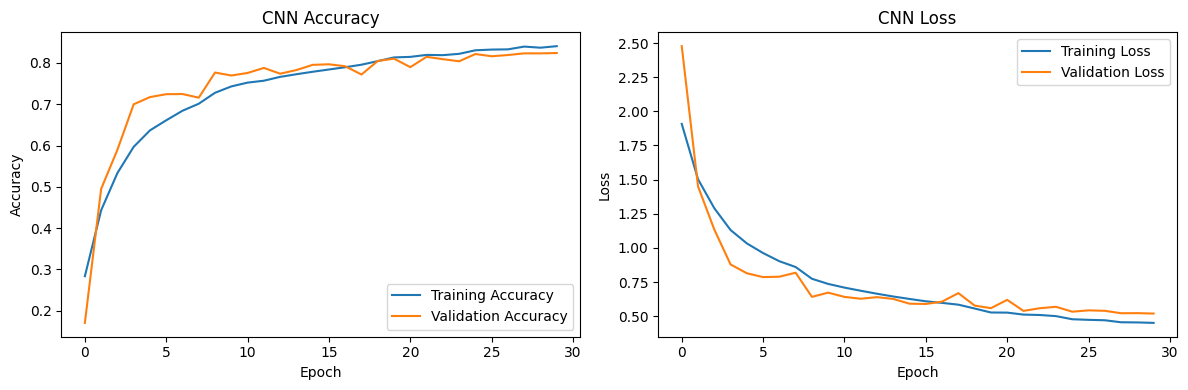

In [ ]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Evaluate each class and create a confusion matrix

              precision    recall  f1-score   support

    airplane     0.8278    0.8030    0.8152      1000
  automobile     0.9063    0.8900    0.8981      1000
        bird     0.7830    0.6640    0.7186      1000
         cat     0.6496    0.6100    0.6292      1000
        deer     0.7627    0.8130    0.7870      1000
         dog     0.6862    0.7370    0.7107      1000
        frog     0.8197    0.8820    0.8497      1000
       horse     0.8742    0.8410    0.8573      1000
        ship     0.8879    0.9030    0.8954      1000
       truck     0.8499    0.9060    0.8771      1000

    accuracy                         0.8049     10000
   macro avg     0.8047    0.8049    0.8038     10000
weighted avg     0.8047    0.8049    0.8038     10000



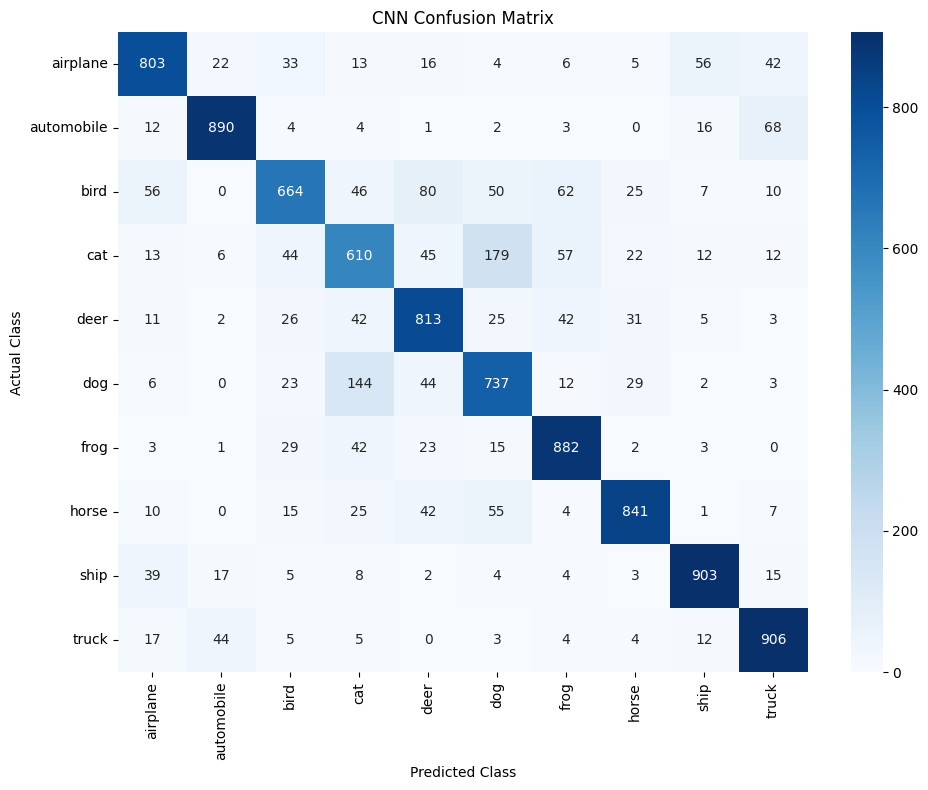

In [ ]:
# Generate class predictions on the test set
y_pred_prob = cnn_model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Print precision, recall, F1-score and class-wise performance
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

# Build the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

Predict a single image

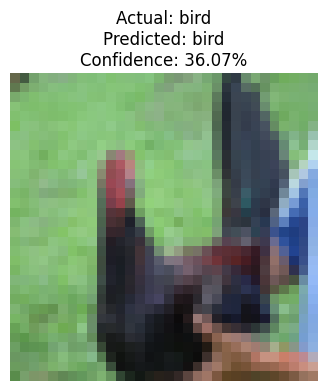

In [ ]:
# Select one test image
image_index = 25
image = x_test[image_index]

# Predict its class
probabilities = cnn_model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)[0]

predicted_class = np.argmax(probabilities)
actual_class = y_test[image_index]

# Visualize the prediction
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(
    f"Actual: {class_names[actual_class]}\n"
    f"Predicted: {class_names[predicted_class]}\n"
    f"Confidence: {probabilities[predicted_class] * 100:.2f}%"
)
plt.axis("off")
plt.show()

Improve the CNN using data augmentation

In [ ]:
# Create random image transformations for training
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
])

# Build an augmented CNN
def build_augmented_cnn():

    inputs = keras.Input(shape=(32, 32, 3))

    # Apply augmentation only during training
    x = data_augmentation(inputs)

    # Extract features at increasing levels of complexity
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(10, activation="softmax")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

aug_model = build_augmented_cnn()

# Train the augmented CNN
history_aug = aug_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=35,
    batch_size=128,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            "best_augmented_cnn.keras",
            monitor="val_accuracy",
            save_best_only=True,
            mode="max"
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=6,
            restore_best_weights=True,
            mode="max"
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ],
    verbose=1
)

# Evaluate the augmented model
aug_model = keras.models.load_model("best_augmented_cnn.keras")
aug_loss, aug_accuracy = aug_model.evaluate(x_test, y_test, verbose=0)

print(f"Augmented CNN test accuracy: {aug_accuracy * 100:.2f}%")

Epoch 1/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.3347 - loss: 1.7831 - val_accuracy: 0.1860 - val_loss: 2.9813 - learning_rate: 0.0010
Epoch 2/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.4618 - loss: 1.4786 - val_accuracy: 0.4622 - val_loss: 1.5331 - learning_rate: 0.0010
Epoch 3/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.5148 - loss: 1.3456 - val_accuracy: 0.4250 - val_loss: 1.8045 - learning_rate: 0.0010
Epoch 4/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.5491 - loss: 1.2524 - val_accuracy: 0.5256 - val_loss: 1.4480 - learning_rate: 0.0010
Epoch 5/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.5748 - loss: 1.1901 - val_accuracy: 0.5436 - val_loss: 1.4057 - learning_rate: 0.0010
Epoch 6/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.5988 - loss: 1.1372 - val_accuracy: 0.6038 - val_loss: 1.1221 - learning_rate: 0.0010
Epoch 7/35
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.6143 - loss: 1

Transfer learning with MobileNetV2

In [ ]:
# Enable mixed precision for NVIDIA T4 GPU
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

tf.keras.mixed_precision.set_global_policy("mixed_float16")

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Precision policy:", tf.keras.mixed_precision.global_policy())


# Build the MobileNetV2 transfer-learning model
def build_mobilenet_model():

    # Define the input image shape
    inputs = keras.Input(shape=(32, 32, 3))

    # Resize CIFAR-10 images for the pretrained network
    x = layers.Resizing(96, 96)(inputs)

    # Convert pixel values from [0, 1] to [-1, 1]
    x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

    # Apply mild augmentation during training only
    x = layers.RandomFlip("horizontal")(x)
    x = layers.RandomTranslation(0.05, 0.05)(x)

    # Load pretrained MobileNetV2 feature extractor
    base_model = keras.applications.MobileNetV2(
        input_shape=(96, 96, 3),
        include_top=False,
        weights="imagenet"
    )

    # Freeze pretrained layers for the initial training stage
    base_model.trainable = False

    x = base_model(x, training=False)

    # Convert feature maps into a feature vector
    x = layers.GlobalAveragePooling2D()(x)

    # Reduce overfitting
    x = layers.Dropout(0.3)(x)

    # Keep output in float32 for numerical stability
    outputs = layers.Dense(
        10,
        activation="softmax",
        dtype="float32"
    )(x)

    model = keras.Model(inputs, outputs)

    # Compile the classification head
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Create the model
mobile_model = build_mobilenet_model()

# Save the best initial model using validation accuracy
initial_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "mobilenet_stage1_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train the new classification head
start_time = time.perf_counter()

history_mobile = mobile_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=128,
    callbacks=initial_callbacks,
    verbose=1
)

initial_training_time = time.perf_counter() - start_time

# Restore the best checkpoint
mobile_model = keras.models.load_model("mobilenet_stage1_best.keras")

# Evaluate the initial model
mobile_loss, mobile_accuracy = mobile_model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Initial test accuracy: {mobile_accuracy * 100:.2f}%")
print(f"Initial training time: {initial_training_time:.2f} seconds")


# --------------------------------------------------
# Stage 2: Fine-tune the final pretrained layers
# --------------------------------------------------

# Locate the MobileNetV2 backbone
base_model = next(
    layer for layer in mobile_model.layers
    if isinstance(layer, keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# Unfreeze the backbone, then freeze earlier layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best fine-tuned model
fine_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "mobilenet_finetuned_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# Fine-tune the model
fine_start = time.perf_counter()

history_fine = mobile_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=12,
    batch_size=128,
    callbacks=fine_callbacks,
    verbose=1
)

fine_training_time = time.perf_counter() - fine_start

# Load the best fine-tuned checkpoint
mobile_model = keras.models.load_model(
    "mobilenet_finetuned_best.keras"
)

# Final evaluation on the test set
fine_loss, fine_accuracy = mobile_model.evaluate(
    x_test, y_test, verbose=0
)

print("\nFinal MobileNetV2 Results")
print(f"Test loss: {fine_loss:.4f}")
print(f"Test accuracy: {fine_accuracy * 100:.2f}%")
print(f"Fine-tuning time: {fine_training_time:.2f} seconds")

# Save the final model
mobile_model.save("cifar10_mobilenetv2_final.keras")
print("Model saved successfully.")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Precision policy: <DTypePolicy "mixed_float16">
Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6070 - loss: 1.2378
Epoch 1: val_accuracy improved from None to 0.84580, saving model to mobilenet_stage1_best.keras

Epoch 1: finished saving model to mobilenet_stage1_best.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 51ms/step - accuracy: 0.7255 - loss: 0.8329 - val_accuracy: 0.8458 - val_loss: 0.4457 - learning_rate: 0.0010
Epoch 2/15
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8087 - loss: 0.5670
Epoch 2: val_accuracy improved from 0.84580 to 0.86340, saving model to mobilenet_stage1_best.keras

Epoch 2: finished saving model to mobilenet_stage1_best.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.8131 - loss: 0.5529 - val_accuracy: 0.8634 - val_loss: 0.4070 - learning_rate: 0.0010
Epoch 3/15
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8244 - loss: 0.5085
Epoch 3: v

Compare the models

Model Performance Comparison


,Model,Test Accuracy (%)
0,MobileNetV2 (Fine-tuned),90.03
1,MobileNetV2 (Initial),85.95
2,Basic CNN,80.49
3,Augmented CNN,71.64


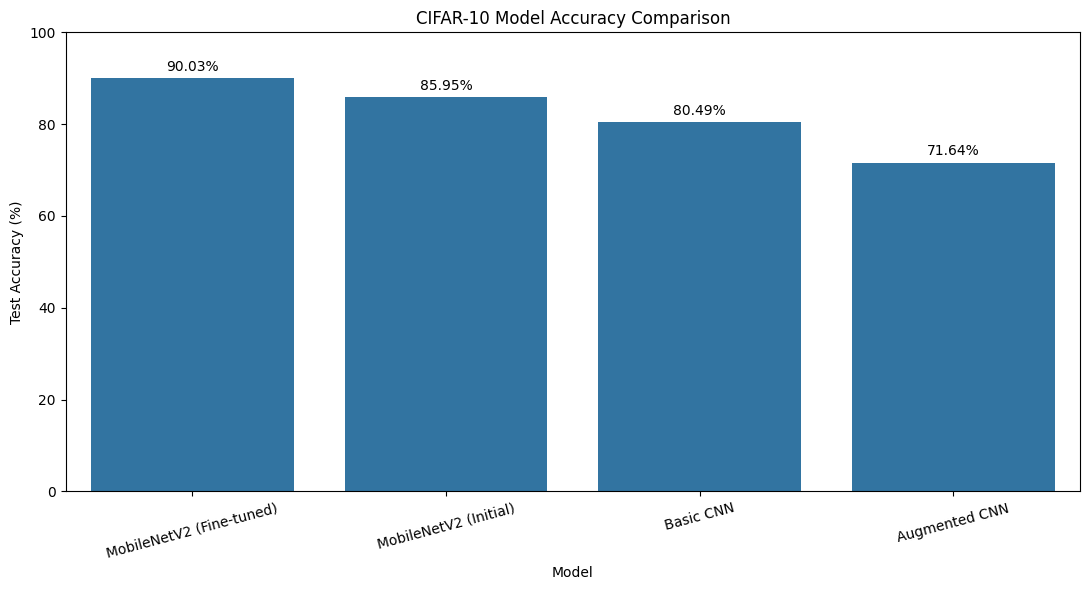

Best model: MobileNetV2 (Fine-tuned)
Test accuracy: 90.03%


In [ ]:
# Collect test performance of all trained models
results = pd.DataFrame({
    "Model": [
        "Basic CNN",
        "Augmented CNN",
        "MobileNetV2 (Initial)",
        "MobileNetV2 (Fine-tuned)"
    ],
    "Test Accuracy (%)": [
        cnn_accuracy * 100,
        aug_accuracy * 100,
        mobile_accuracy * 100,
        fine_accuracy * 100
    ]
})

# Sort models by test accuracy
results = results.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

# Display the comparison table
print("Model Performance Comparison")
display(results.round(2))

# Plot model accuracy
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=results,
    x="Model",
    y="Test Accuracy (%)"
)

# Display accuracy values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("CIFAR-10 Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Identify the model with the highest test accuracy
best_model_name = results.iloc[0]["Model"]
best_accuracy = results.iloc[0]["Test Accuracy (%)"]

print(f"Best model: {best_model_name}")
print(f"Test accuracy: {best_accuracy:.2f}%")

Save the best model

In [ ]:
# Select the model with the highest test accuracy for this experiment
model_candidates = {
    "Basic CNN": cnn_model,
    "Augmented CNN": aug_model,
    "MobileNetV2": mobile_model
}

best_name = results.iloc[0]["Model"]
best_model = model_candidates[best_name]

# Save the selected model
best_model.save("cifar10_best_model.keras")

print("Selected model:", best_name)
print("Saved as: cifar10_best_model.keras")

# Download the saved model from Google Colab
from google.colab import files
files.download("cifar10_best_model.keras")

Selected model: MobileNetV2
Saved as: cifar10_best_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>